# What drives pulmonary ventilation (VE)?

HazeWise turns a planned activity into an inhaled PM2.5 dose:

$$\text{intake}\ (\mu g) = \text{PM2.5}\ (\mu g/m^3) \times \frac{VE\ (L/min)}{1000} \times \text{duration}\ (min)$$

PM2.5 comes from NEA forecasts. VE has to come from the activity. This notebook uses 992 graded treadmill tests
from the University of Málaga exercise physiology lab (PhysioNet, breath-by-breath) to see what VE depends on and how
well we can predict it from things the app can actually know: pace, age, sex, weight, height, and maybe heart rate.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from matplotlib.colors import LinearSegmentedColormap
from scipy.optimize import curve_fit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold

DATA = Path("data/treadmill-maximal-exercise-tests-from-the-exercise-physiology-and-human-performance-lab-of-the-university-of-malaga-1.0.1")

# chart tokens (light mode)
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#184f95", "#3987e5", "#f0efec", "#e66767", "#b8302f"])

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "figure.dpi": 110, "font.family": ["Helvetica Neue", "Helvetica", "Arial", "sans-serif"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "grid.linestyle": "-", "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 1.8, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "axes.prop_cycle": plt.cycler(color=C),
    "legend.frameon": False, "legend.fontsize": 9, "legend.labelcolor": INK2,
})
pd.set_option("display.precision", 2)
pd.set_option("display.width", 140)


def binned(df, x, y, edges, min_tests=30):
    # median + IQR of y in bins of x, keeping bins with enough distinct tests
    cut = pd.cut(df[x], edges)
    g = df.groupby(cut, observed=True)
    out = g[y].quantile([0.25, 0.5, 0.75]).unstack()
    out.columns = ["q25", "med", "q75"]
    out["n_tests"] = g["ID_test"].nunique()
    out["x"] = [iv.mid for iv in out.index]
    return out[out.n_tests >= min_tests].reset_index(drop=True)


def band(ax, b, color, label=None, alpha=0.12):
    ax.fill_between(b.x, b.q25, b.q75, color=color, alpha=alpha, lw=0)
    ax.plot(b.x, b.med, color=color, label=label)

## 1. Data

Two files. `test_measure.csv` holds one row per breath. `subject-info.csv` holds one row per test, with the
subject profile and the lab's temperature and humidity on test day.

In [2]:
meas = pd.read_csv(DATA / "test_measure.csv")
subj = pd.read_csv(DATA / "subject-info.csv")
print(f"{len(meas):,} breaths | {meas.ID_test.nunique()} tests | {meas.ID.nunique()} subjects")
print(f"{(subj.groupby('ID').size() > 1).sum()} subjects did more than one test (max {subj.groupby('ID').size().max()})")

units = pd.DataFrame({
    "column": ["time", "Speed", "HR", "VO2", "VCO2", "RR", "VE", "Age", "Weight", "Height", "Humidity", "Temperature", "Sex"],
    "unit": ["s from test start", "km/h", "beats/min", "mL/min", "mL/min", "breaths/min", "L/min", "years", "kg", "cm",
             "% (lab)", "°C (lab)", "0/1"],
})
display(units.set_index("column").T)
display(meas.describe().T[["count", "mean", "std", "min", "50%", "max"]])

575,087 breaths | 992 tests | 857 subjects
116 subjects did more than one test (max 5)


column,time,Speed,HR,VO2,VCO2,RR,VE,Age,Weight,Height,Humidity,Temperature,Sex
unit,s from test start,km/h,beats/min,mL/min,mL/min,breaths/min,L/min,years,kg,cm,% (lab),°C (lab),0/1


,count,mean,std,min,50%,max
time,575087.0,628.13,325.59,0.0,646.0,1712.0
Speed,575087.0,9.61,4.52,0.0,9.0,23.1
HR,574106.0,146.94,32.21,0.0,153.0,226.0
VO2,570216.0,2313.62,978.10,-5.0,2309.0,6217.0
VCO2,570216.0,2390.08,1159.79,51.0,2320.0,7566.0
RR,575087.0,36.49,12.18,2.0,36.0,113.0
VE,575087.0,69.30,33.56,1.8,66.3,207.1
ID,575087.0,425.42,245.44,1.0,431.0,857.0


In [3]:
# Sex is a 0/1 code. Check which way round it is from body size.
display(subj.groupby("Sex")[["Height", "Weight", "Age"]].agg(["mean", "count"]).round(1))

Height       Weight         Age      
      mean count   mean count  mean count
Sex                                      
0    176.3   843   75.3   843  29.5   843
1    166.8   149   62.7   149  26.0   149

Sex = 1 is shorter and lighter by about 10 cm and 13 kg, which agrees with the dataset description (1 = female).
Females are 15% of tests. The sample is mostly young-ish men who were fit enough to want a lab test, and that matters
later.

The dataset description says VO2, VCO2 and VE are missing for 30 tests. Checking that against the file:

### Cleaning

Breath-by-breath gas data is noisy. Swallows, coughs and sighs produce single-breath spikes, and the HR strap
drops out (HR = 0, or sudden 50 bpm dips). The plan:

* HR < 40 and VO2/VCO2 ≤ 0 become missing.
* A breath whose HR is more than 20 bpm off its 15-breath rolling median becomes missing HR.
* A breath whose VE is more than 50% off its 7-breath rolling median gets flagged. Analyses use 10 s medians, which
  already damp single breaths, and flagged breaths are dropped before binning.
* Tidal volume VT = VE / RR (L per breath).

In [4]:
gas_missing = meas.groupby("ID_test").VO2.apply(lambda x: x.isna().all())
lab_missing = subj.set_index("ID_test")[["Humidity", "Temperature"]].isna().any(axis=1)
print(f"tests with no VO2/VCO2 at all: {gas_missing.sum()}")
print(f"tests with any missing VE: {meas.groupby('ID_test').VE.apply(lambda x: x.isna().any()).sum()}")
print(f"tests missing lab humidity/temperature: {lab_missing.sum()}  (overlap with no-gas tests: {(gas_missing & lab_missing).sum()})")
ve10 = meas[meas.Speed.between(9.8, 10.2)].groupby(meas.ID_test.isin(gas_missing[gas_missing].index)).VE.median()
print(f"median VE at 10 km/h: tests with gas data {ve10[False]:.1f}, tests without {ve10[True]:.1f} L/min")

tests with no VO2/VCO2 at all: 11
tests with any missing VE: 0
tests missing lab humidity/temperature: 30  (overlap with no-gas tests: 0)
median VE at 10 km/h: tests with gas data 61.2, tests without 61.5 L/min


Only 11 tests lack gas data, and VE is present in all of them at normal-looking values. The "30" in the description
matches the 30 tests without lab humidity/temperature, which are different tests. So the 11 stay in the VE analyses.
They drop out of the model comparison in section 12, because the lab-ceiling model needs VO2.

In [5]:
m = meas.sort_values(["ID_test", "time"]).reset_index(drop=True)
n0 = len(m)
m.loc[m.HR < 40, "HR"] = np.nan
m.loc[(m.VO2 <= 0) | (m.VCO2 <= 0), ["VO2", "VCO2"]] = np.nan

g = m.groupby("ID_test")
hr_med = g.HR.transform(lambda s: s.rolling(15, center=True, min_periods=5).median())
hr_bad = (m.HR - hr_med).abs() > 20
m.loc[hr_bad, "HR"] = np.nan

ve_med = g.VE.transform(lambda s: s.rolling(7, center=True, min_periods=3).median())
ve_bad = (m.VE - ve_med).abs() > 0.5 * ve_med
m["VT"] = m.VE / m.RR

print(f"HR missing after cleaning: {m.HR.isna().mean():.1%} (strap glitches flagged: {hr_bad.mean():.1%})")
print(f"VO2/VCO2 missing: {m.VO2.isna().mean():.1%}")
print(f"VE spike breaths dropped: {ve_bad.sum():,} ({ve_bad.mean():.1%})")
m = m[~ve_bad].copy()

HR missing after cleaning: 0.5% (strap glitches flagged: 0.3%)
VO2/VCO2 missing: 0.8%
VE spike breaths dropped: 105 (0.0%)


## 2. Protocol and phases

Every test follows the same shape: a few minutes walking at about 5 km/h, then a continuous ramp of +0.1 km/h about
every 6 s (≈ 1 km/h per minute) at flat grade until exhaustion, then walking recovery. Some tests start with a short
standing period. Each breath gets a phase label:

* `rest`: belt stopped before the ramp
* `warmup`: walking at the starting speed
* `ramp`: from the first speed increase to the peak speed
* `recovery`: after the speed drops from peak

In [6]:
g = m.groupby("ID_test")
pk = g.Speed.transform("max")
recovery = (m.Speed == pk).groupby(m.ID_test).cummax() & (m.Speed < pk)
moving = m.Speed > 0
t_move0 = m.time.where(moving).groupby(m.ID_test).transform("min")
warm_speed = m.Speed.where(moving & (m.time < t_move0 + 60)).groupby(m.ID_test).transform("median")
pre = ~recovery
t_ramp0 = m.time.where(pre & (m.Speed <= warm_speed + 0.05)).groupby(m.ID_test).transform("max")

m["phase"] = np.select(
    [recovery, pre & (m.time > t_ramp0), pre & moving, pre & ~moving],
    ["recovery", "ramp", "warmup", "rest"], default="other")
m["t_phase"] = m.time - m.groupby(["ID_test", "phase"]).time.transform("min")

dur = m.groupby(["ID_test", "phase"]).time.agg(lambda t: t.max() - t.min()).unstack()
print("phase duration per test (s)")
display(dur.describe().T[["count", "mean", "50%", "min", "max"]])

tests = pd.DataFrame({
    "peak_speed": g.Speed.max(),
    "warm_speed": warm_speed.groupby(m.ID_test).first(),
    "ramp_rate": m[m.phase == "ramp"].groupby("ID_test").apply(
        lambda d: np.polyfit(d.time, d.Speed, 1)[0] * 60 if len(d) > 10 else np.nan, include_groups=False),
}).join(subj.set_index("ID_test"))
print(f"ramp rate km/h per min: median {tests.ramp_rate.median():.2f}, IQR {tests.ramp_rate.quantile(.25):.2f}-{tests.ramp_rate.quantile(.75):.2f}")
print(f"peak speed km/h: median {tests.peak_speed.median():.1f}, range {tests.peak_speed.min():.1f}-{tests.peak_speed.max():.1f}")

phase duration per test (s)


,count,mean,50%,min,max
phase,,,,,
ramp,992.0,665.10,683.0,150.0,1163.0
recovery,992.0,198.04,187.0,62.0,747.0
rest,211.0,69.21,56.0,0.0,385.0
warmup,992.0,208.71,174.0,24.0,855.0


ramp rate km/h per min: median 1.00, IQR 0.99-1.00
peak speed km/h: median 16.7, range 7.0-23.1


Everything below runs on 10 s medians per test and phase. That keeps the time resolution (one bin ≈ 0.17 km/h of
ramp) and gets rid of breath-level noise.

In [7]:
m["tbin"] = (m.time // 10).astype(int)
cols = ["time", "t_phase", "Speed", "HR", "VO2", "VCO2", "RR", "VE", "VT"]
bins = (m.groupby(["ID_test", "ID", "phase", "tbin"], observed=True)[cols].median().reset_index()
        .merge(subj.drop(columns="ID"), on="ID_test", how="left")
        .sort_values(["ID_test", "time"]).reset_index(drop=True))

tb = bins.groupby("ID_test")
bins["VE_peak"] = tb.VE.transform("max")
bins["HR_peak"] = tb.HR.transform("max")
bins["speed_peak"] = tb.Speed.transform("max")
bins["speed_rel"] = bins.Speed / bins.speed_peak
bins["HR_rel"] = bins.HR / bins.HR_peak
bins["VE_rel"] = bins.VE / bins.VE_peak
bins["VO2_kg"] = bins.VO2 / bins.Weight            # mL/kg/min
bins["EqO2"] = bins.VE * 1000 / bins.VO2           # ventilatory equivalent for O2
bins["EqCO2"] = bins.VE * 1000 / bins.VCO2
bins["sex_label"] = bins.Sex.map({0: "male", 1: "female"})
tests["VO2peak_kg"] = tb.VO2.max() / tests.Weight
tests["VE_peak"] = tb.VE.max()

# working set for "during exercise": ramp plus warm-up after the first minute
ex = bins[(bins.phase == "ramp") | ((bins.phase == "warmup") & (bins.t_phase >= 60))].copy()
print(f"{len(bins):,} bins total, {len(ex):,} exercise bins")

110,476 bins total, 82,312 exercise bins


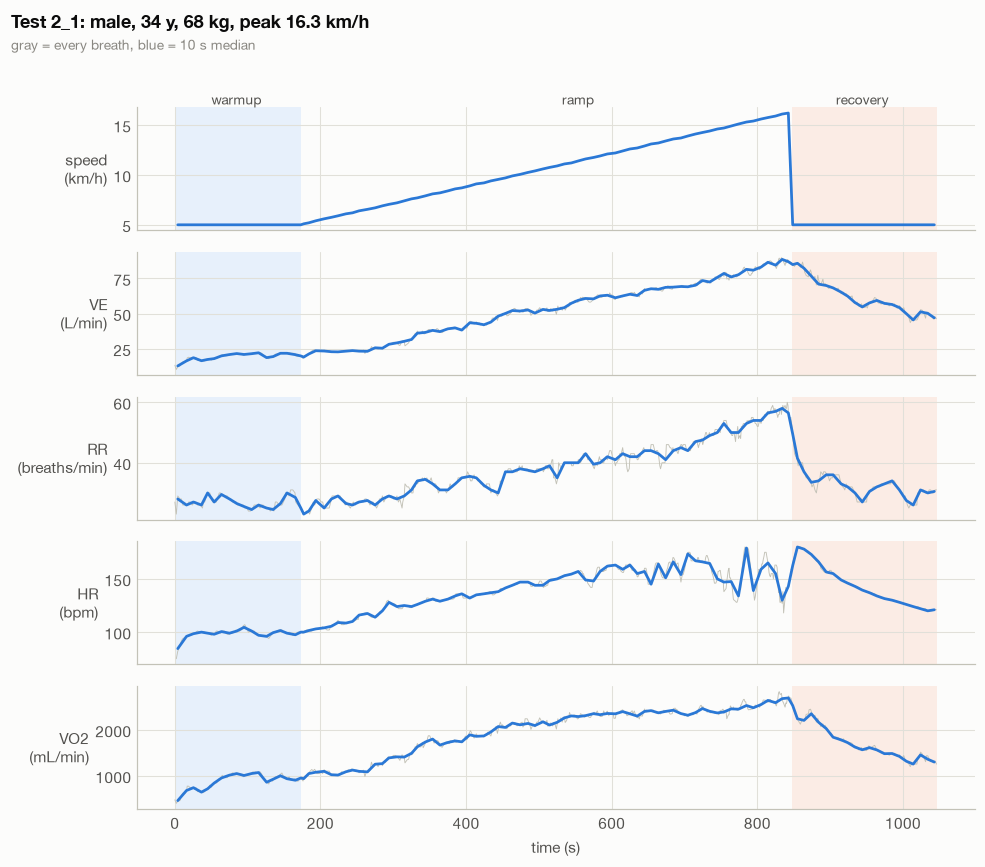

In [8]:
def plot_test(test_id):
    d = m[m.ID_test == test_id]
    b = bins[bins.ID_test == test_id]
    panels = [("Speed", "speed\n(km/h)"), ("VE", "VE\n(L/min)"), ("RR", "RR\n(breaths/min)"),
              ("HR", "HR\n(bpm)"), ("VO2", "VO2\n(mL/min)")]
    fig, axes = plt.subplots(len(panels), 1, figsize=(9, 8), sharex=True)
    shades = {"rest": "#f0efec", "warmup": "#e7f0fb", "recovery": "#fbece5"}
    for ax, (col, lab) in zip(axes, panels):
        for ph, colr in shades.items():
            t = d.time[d.phase == ph]
            if len(t):
                ax.axvspan(t.min(), t.max(), color=colr, lw=0, zorder=0)
        if col != "Speed":
            ax.plot(d.time, d[col], color=AXIS, lw=0.6, zorder=1)
        ax.plot(b.time, b[col], color=C[0], zorder=2)
        ax.set_ylabel(lab, rotation=0, ha="right", va="center")
    for ph in ["warmup", "ramp", "recovery"]:
        t = d.time[d.phase == ph]
        axes[0].text(t.mean(), axes[0].get_ylim()[1], ph, ha="center", va="bottom", color=INK2, fontsize=9)
    axes[-1].set_xlabel("time (s)")
    r = tests.loc[test_id]
    fig.suptitle(f"Test {test_id}: {'female' if r.Sex else 'male'}, {r.Age:.0f} y, {r.Weight:.0f} kg, peak {r.peak_speed:.1f} km/h",
                 x=0.01, ha="left", fontweight="bold")
    fig.text(0.01, 0.935, "gray = every breath, blue = 10 s median", color=MUTED, fontsize=9)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

plot_test("2_1")

## 3. Correlations

Spearman rank correlation over exercise bins (ramp + steady warm-up). Spearman because most relations here are
monotonic but curved.

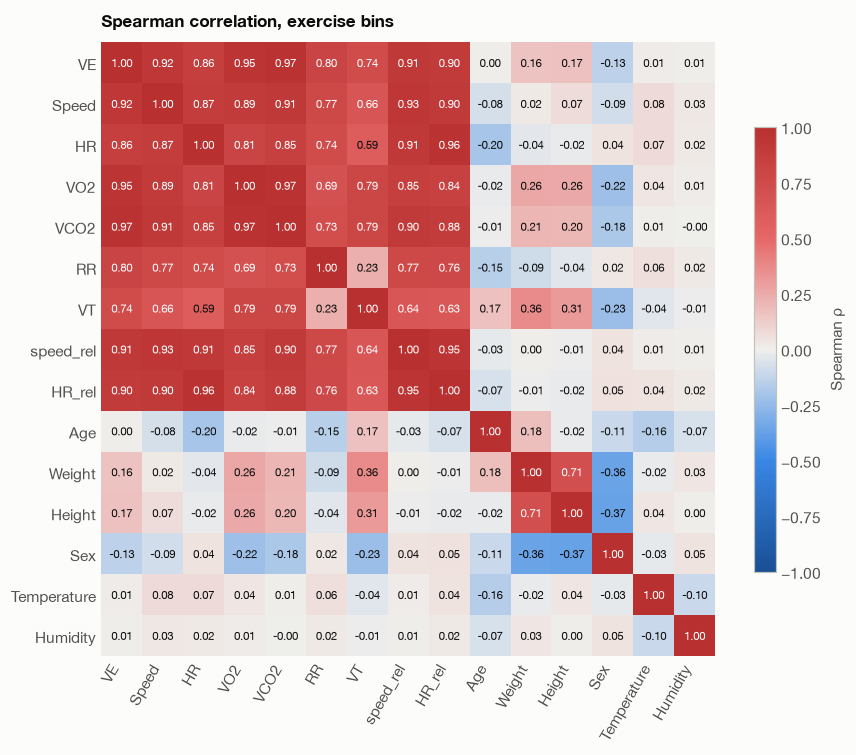

Correlation with VE, sorted:


,VCO2,VO2,Speed,speed_rel,HR_rel,HR,RR,VT,Height,Weight,Sex,Temperature,Humidity,Age
ρ with VE,0.97,0.95,0.92,0.91,0.9,0.86,0.8,0.74,0.17,0.16,-0.13,0.01,6.41e-03,3.88e-03


In [9]:
corr_cols = ["VE", "Speed", "HR", "VO2", "VCO2", "RR", "VT", "speed_rel", "HR_rel", "Age", "Weight", "Height", "Sex",
             "Temperature", "Humidity"]
cm = ex[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
ax.grid(False)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = cm.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else INK)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman ρ")
ax.set_title("Spearman correlation, exercise bins")
plt.show()

print("Correlation with VE, sorted:")
display(cm.VE.drop("VE").sort_values(key=abs, ascending=False).to_frame("ρ with VE").T)

## 4. VE against speed

Speed is the main input the app gets from a plan like "10 km at 7 min/km". This is the core curve.

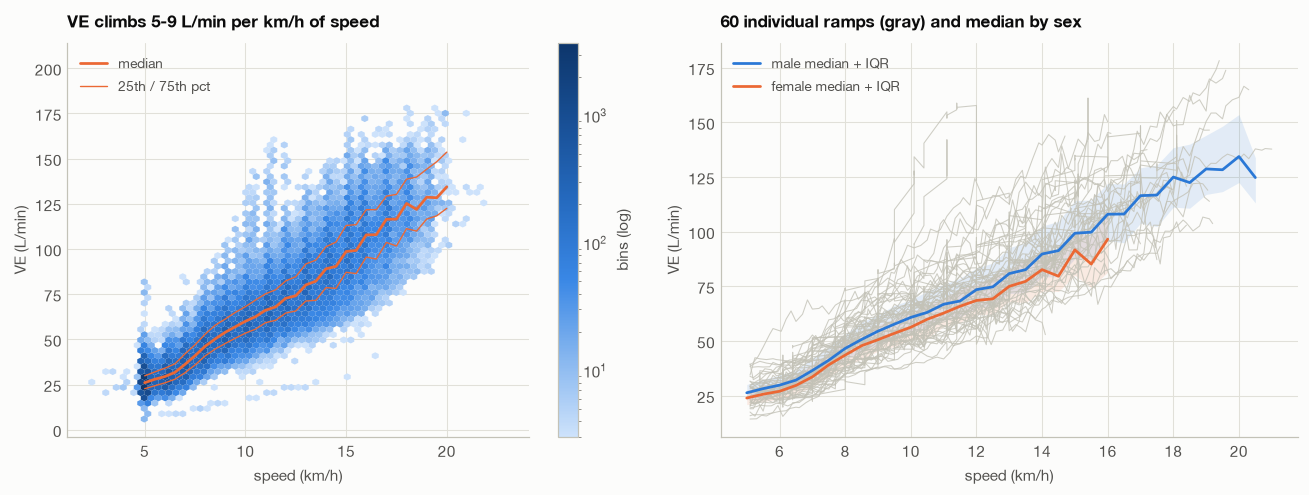

,q25,med,q75,n_tests,IQR / median
speed km/h,,,,,
5.0,22.70,26.00,29.80,898,0.27
7.0,31.50,36.15,41.90,983,0.29
8.5,44.60,50.20,57.80,793,0.26
10.0,53.40,60.00,68.05,974,0.24
12.0,64.53,72.70,82.30,923,0.24
14.0,78.60,89.00,101.25,824,0.25
16.0,95.53,107.80,121.75,636,0.24
18.0,111.25,125.20,138.64,303,0.22


In [10]:
edges = np.arange(4.75, 22.3, 0.5)
b_all = binned(ex, "Speed", "VE", edges)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
hb = ax.hexbin(ex.Speed, ex.VE, gridsize=60, cmap=SEQ, bins="log", mincnt=3, linewidths=0)
ax.plot(b_all.x, b_all.med, color=C[1], label="median")
ax.plot(b_all.x, b_all.q25, color=C[1], lw=0.9, label="25th / 75th pct")
ax.plot(b_all.x, b_all.q75, color=C[1], lw=0.9)
ax.set(xlabel="speed (km/h)", ylabel="VE (L/min)", title="VE climbs 5-9 L/min per km/h of speed")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="bins (log)")

ax = axes[1]
rng = np.random.default_rng(0)
for tid in rng.choice(ex.ID_test.unique(), 60, replace=False):
    d = ex[(ex.ID_test == tid) & (ex.phase == "ramp")]
    ax.plot(d.Speed, d.VE, color=AXIS, lw=0.7, alpha=0.8)
for k, (sex, lab) in enumerate([(0, "male"), (1, "female")]):
    band(ax, binned(ex[ex.Sex == sex], "Speed", "VE", edges, min_tests=15), C[k], f"{lab} median + IQR")
ax.set(xlabel="speed (km/h)", ylabel="VE (L/min)", title="60 individual ramps (gray) and median by sex")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

tbl = b_all.set_index("x").loc[[5.0, 7.0, 8.5, 10.0, 12.0, 14.0, 16.0, 18.0], ["q25", "med", "q75", "n_tests"]]
tbl.index.name = "speed km/h"
tbl["IQR / median"] = (tbl.q75 - tbl.q25) / tbl.med
display(tbl)

## 5. Fitness changes the curve

At the same speed, a fit runner works at a lower fraction of their capacity. Peak treadmill speed is a decent fitness
proxy here. Split tests into thirds by peak speed and compare against absolute speed and against relative speed
(speed / own peak speed).

,peak_speed,VO2peak_kg,VE_peak,Weight,Age,n
fitness,,,,,,
low,14.00,41.02,106.05,71.6,28.20,334
mid,16.70,48.01,124.45,74.0,27.55,334
high,18.75,53.07,134.35,73.1,26.20,324


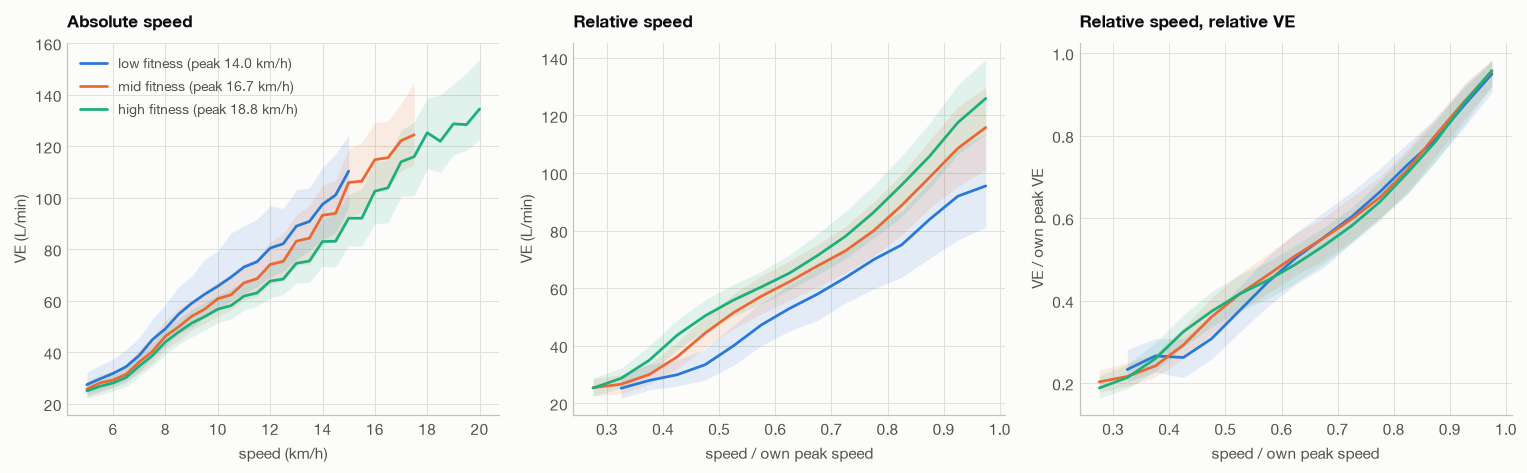

median ramp VE (L/min) by fitness third at whole-number speeds (±0.5 km/h)


speed,8.0,10.0,12.0,14.0
fitness,,,,
low,48.6,66.7,78.5,96.7
mid,45.6,59.9,73.0,91.5
high,43.6,56.4,66.8,81.4


In [11]:
tests["fitness"] = pd.qcut(tests.peak_speed, 3, labels=["low", "mid", "high"])
ex["fitness"] = ex.ID_test.map(tests.fitness)
display(tests.groupby("fitness", observed=True)[["peak_speed", "VO2peak_kg", "VE_peak", "Weight", "Age"]].median()
        .assign(n=tests.fitness.value_counts()))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for k, f in enumerate(["low", "mid", "high"]):
    d = ex[ex.fitness == f]
    lab = f"{f} fitness (peak {tests.peak_speed[tests.fitness == f].median():.1f} km/h)"
    band(axes[0], binned(d, "Speed", "VE", edges), C[k], lab)
    band(axes[1], binned(d, "speed_rel", "VE", np.arange(0.25, 1.03, 0.05)), C[k], lab)
    band(axes[2], binned(d, "speed_rel", "VE_rel", np.arange(0.25, 1.03, 0.05)), C[k], lab)
axes[0].set(xlabel="speed (km/h)", ylabel="VE (L/min)", title="Absolute speed")
axes[1].set(xlabel="speed / own peak speed", ylabel="VE (L/min)", title="Relative speed")
axes[2].set(xlabel="speed / own peak speed", ylabel="VE / own peak VE", title="Relative speed, relative VE")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

print("median ramp VE (L/min) by fitness third at whole-number speeds (±0.5 km/h)")
display(ex[ex.phase == "ramp"].assign(speed=lambda t: t.Speed.round()).query("speed in [8, 10, 12, 14]")
        .groupby(["fitness", "speed"], observed=True).VE.median().unstack().round(1))

## 6. VE and gas exchange

Ventilation is driven by CO2 output. VO2 and VCO2 are not available in the app, but they explain why the speed curve
bends: above the ventilatory threshold, lactate buffering adds extra CO2 and VE climbs faster than O2 demand.

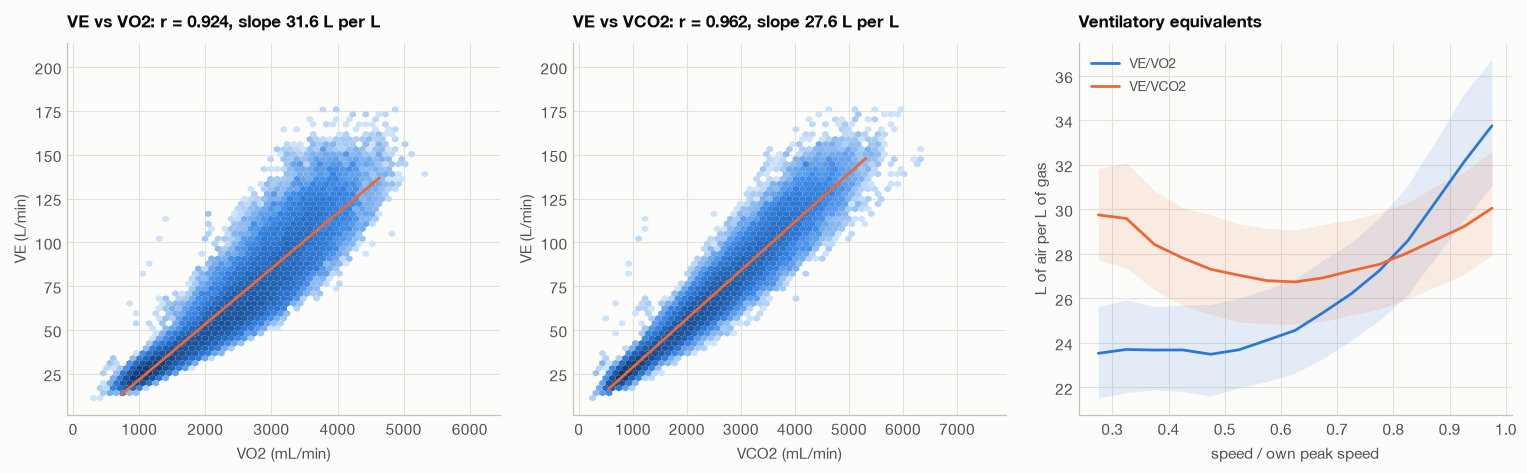

In [12]:
d = ex.dropna(subset=["VO2", "VCO2"])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, col in zip(axes[:2], ["VO2", "VCO2"]):
    ax.hexbin(d[col], d.VE, gridsize=60, cmap=SEQ, bins="log", mincnt=3, linewidths=0)
    fit = np.polyfit(d[col], d.VE, 1)
    r = np.corrcoef(d[col], d.VE)[0, 1]
    xs = np.linspace(d[col].quantile(0.005), d[col].quantile(0.995), 50)
    ax.plot(xs, np.polyval(fit, xs), color=C[1])
    ax.set(xlabel=f"{col} (mL/min)", ylabel="VE (L/min)",
           title=f"VE vs {col}: r = {r:.3f}, slope {fit[0] * 1000:.1f} L per L")

ax = axes[2]
rel_edges = np.arange(0.25, 1.03, 0.05)
band(ax, binned(d, "speed_rel", "EqO2", rel_edges), C[0], "VE/VO2")
band(ax, binned(d, "speed_rel", "EqCO2", rel_edges), C[1], "VE/VCO2")
ax.set(xlabel="speed / own peak speed", ylabel="L of air per L of gas",
       title="Ventilatory equivalents")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## 7. Does the ACSM chain work here?

The README plan is pace → VO2 (ACSM metabolic equations) → VE. ACSM on flat ground:

* walking: VO2 = 0.1 × v + 3.5 mL/kg/min, v in m/min
* running: VO2 = 0.2 × v + 3.5 mL/kg/min

Compare against measured VO2/kg on the ramp, then turn ACSM VO2 into VE using the measured VE/VO2 at each speed.

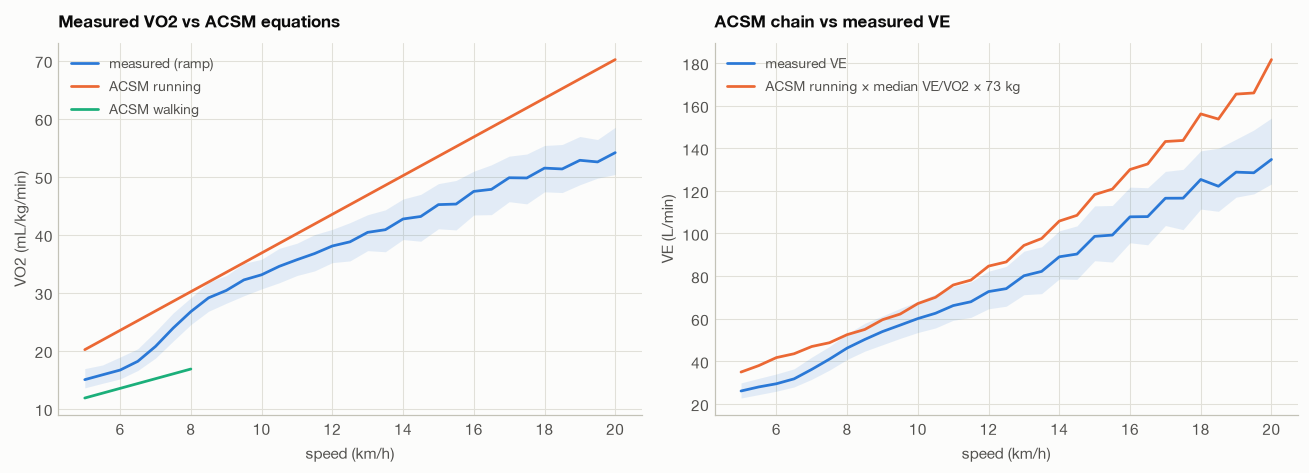

,measured VO2/kg,ACSM running VO2/kg,VO2 measured / ACSM,VE chain / measured
speed km/h,,,,
6.0,16.65,23.50,0.71,1.42
8.0,26.73,30.17,0.89,1.14
10.0,33.08,36.83,0.90,1.12
12.0,38.04,43.50,0.87,1.16
14.0,42.69,50.17,0.85,1.19
16.0,47.45,56.83,0.83,1.21
18.0,51.46,63.50,0.81,1.25


In [13]:
d = ex.dropna(subset=["VO2_kg"])
b_vo2 = binned(d, "Speed", "VO2_kg", edges)
b_eq = binned(d, "Speed", "EqO2", edges)
v = b_vo2.x.to_numpy()
acsm_run = 0.2 * v * 1000 / 60 + 3.5
acsm_walk = 0.1 * v * 1000 / 60 + 3.5

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
band(ax, b_vo2, C[0], "measured (ramp)")
ax.plot(v, acsm_run, color=C[1], label="ACSM running")
ax.plot(v[v <= 8], acsm_walk[v <= 8], color=C[2], label="ACSM walking")
ax.set(xlabel="speed (km/h)", ylabel="VO2 (mL/kg/min)", title="Measured VO2 vs ACSM equations")
ax.legend(loc="upper left")

ax = axes[1]
med_w = d.Weight.median()
ve_chain = acsm_run * med_w * b_eq.set_index("x").med.reindex(v).to_numpy() / 1000
band(ax, binned(d, "Speed", "VE", edges), C[0], "measured VE")
ax.plot(v, ve_chain, color=C[1], label=f"ACSM running × median VE/VO2 × {med_w:.0f} kg")
ax.set(xlabel="speed (km/h)", ylabel="VE (L/min)", title="ACSM chain vs measured VE")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

b_ve = binned(d, "Speed", "VE", edges).set_index("x").med.reindex(v).to_numpy()
cmp = pd.DataFrame({"measured VO2/kg": b_vo2.med.to_numpy(), "ACSM running VO2/kg": acsm_run,
                    "VO2 measured / ACSM": b_vo2.med.to_numpy() / acsm_run, "VE chain / measured": ve_chain / b_ve},
                   index=pd.Index(v, name="speed km/h"))
display(cmp.loc[[6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 18.0]].round(2))

## 8. Breathing pattern

VE = RR × VT. People first breathe deeper, then faster once tidal volume tops out. This also shows why breathing rate
alone (e.g. from a watch) is a weak VE proxy at low intensity.

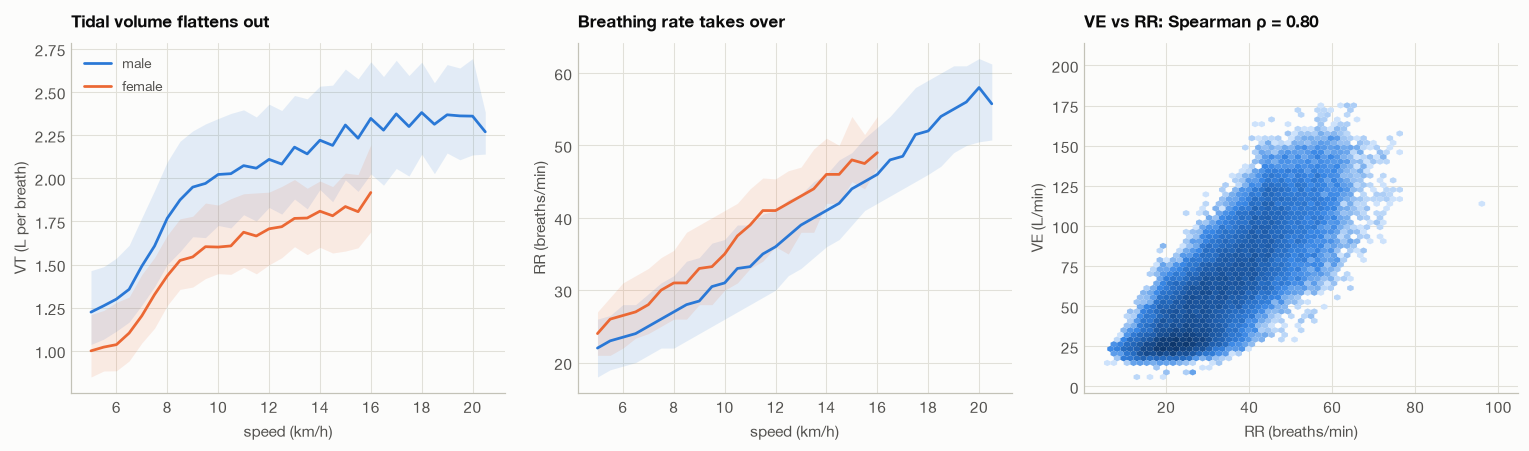

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for k, (sex, lab) in enumerate([(0, "male"), (1, "female")]):
    dd = ex[ex.Sex == sex]
    band(axes[0], binned(dd, "Speed", "VT", edges, 15), C[k], lab)
    band(axes[1], binned(dd, "Speed", "RR", edges, 15), C[k], lab)
axes[0].set(xlabel="speed (km/h)", ylabel="VT (L per breath)", title="Tidal volume flattens out")
axes[1].set(xlabel="speed (km/h)", ylabel="RR (breaths/min)", title="Breathing rate takes over")
axes[0].legend(loc="upper left")
ax = axes[2]
ax.hexbin(ex.RR, ex.VE, gridsize=60, cmap=SEQ, bins="log", mincnt=3, linewidths=0)
ax.set(xlabel="RR (breaths/min)", ylabel="VE (L/min)",
       title=f"VE vs RR: Spearman ρ = {ex[['RR', 'VE']].corr('spearman').iloc[0, 1]:.2f}")
fig.tight_layout()
plt.show()

## 9. Heart rate

HR is the one physiological signal many users can supply from a watch. It carries the person's relative effort, which
speed alone does not.

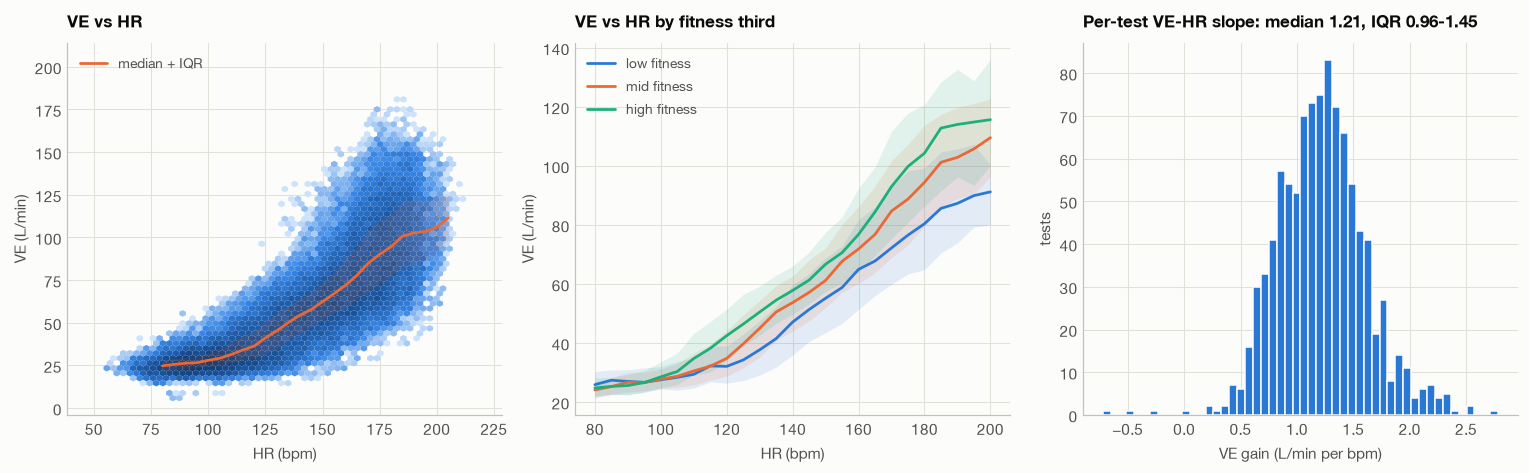

,n tests,median VE,IQR/median
speed 9.8-10.2 km/h,974.0,59.60,0.24
HR 148-152 bpm,944.0,59.74,0.35
HR 70-72% of own peak,886.0,46.00,0.36
speed 50-52% of own peak,790.0,48.26,0.32


In [15]:
d = ex.dropna(subset=["HR"])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
ax = axes[0]
ax.hexbin(d.HR, d.VE, gridsize=60, cmap=SEQ, bins="log", mincnt=3, linewidths=0)
band(ax, binned(d, "HR", "VE", np.arange(77.5, 212, 5)), C[1], "median + IQR")
ax.set(xlabel="HR (bpm)", ylabel="VE (L/min)", title="VE vs HR")
ax.legend(loc="upper left")

ax = axes[1]
for k, f in enumerate(["low", "mid", "high"]):
    band(ax, binned(d[d.fitness == f], "HR", "VE", np.arange(77.5, 212, 5)), C[k], f"{f} fitness")
ax.set(xlabel="HR (bpm)", ylabel="VE (L/min)", title="VE vs HR by fitness third")
ax.legend(loc="upper left")

# per-test linear VE~HR slope on the ramp, above 120 bpm where it is close to linear
slopes = (d[(d.phase == "ramp") & (d.HR > 120)].groupby("ID_test")
          .apply(lambda t: np.polyfit(t.HR, t.VE, 1)[0] if len(t) > 15 else np.nan, include_groups=False).dropna())
ax = axes[2]
ax.hist(slopes, bins=50, color=C[0], edgecolor=SURF, linewidth=1)
ax.set(xlabel="VE gain (L/min per bpm)", ylabel="tests",
       title=f"Per-test VE-HR slope: median {slopes.median():.2f}, IQR {slopes.quantile(.25):.2f}-{slopes.quantile(.75):.2f}")
fig.tight_layout()
plt.show()

# How tight is VE at a fixed input? Compare spread at matched points.
def spread(df, col, lo, hi):
    s = df[(df[col] >= lo) & (df[col] < hi)].groupby("ID_test").VE.median()
    return pd.Series({"n tests": len(s), "median VE": s.median(), "IQR/median": (s.quantile(.75) - s.quantile(.25)) / s.median()})

display(pd.DataFrame({
    "speed 9.8-10.2 km/h": spread(ex, "Speed", 9.8, 10.2),
    "HR 148-152 bpm": spread(d, "HR", 148, 152),
    "HR 70-72% of own peak": spread(d, "HR_rel", 0.70, 0.72),
    "speed 50-52% of own peak": spread(ex, "speed_rel", 0.50, 0.52),
}).T)

## 10. Subject and lab factors

One number per test: VE at 10 km/h on the ramp (≈ 6 min/km). Regress it on profile, fitness, and lab conditions to see
which factors matter once the others are held fixed.

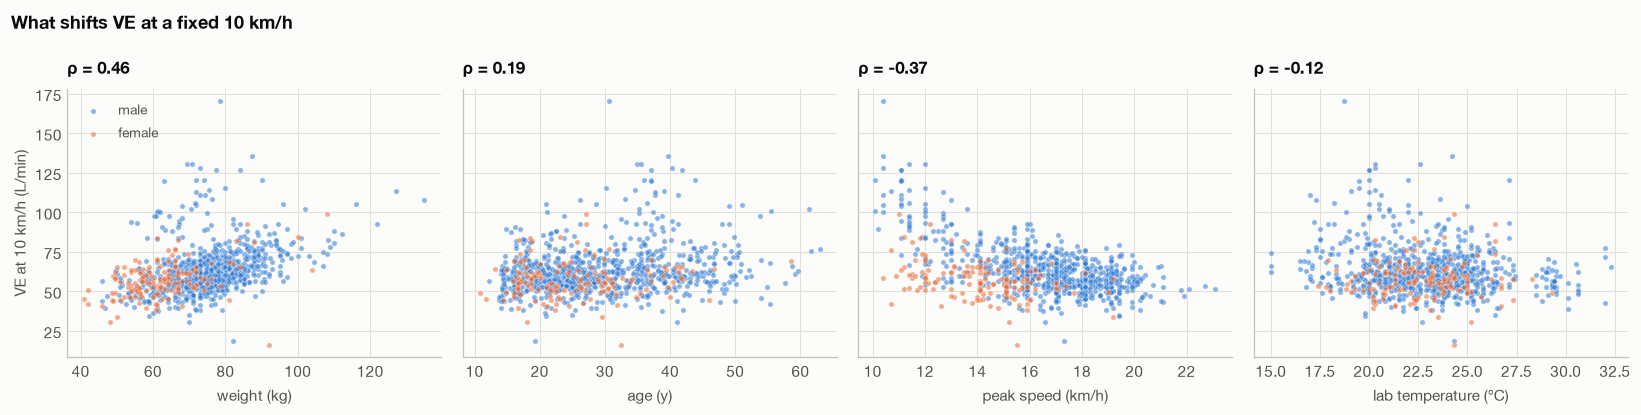

n = 943 tests. R² profile only = 0.19, + fitness & lab = 0.46


,Coef.,Std.Err.,P>|t|,% change in VE per unit
Intercept,3.00e+00,1.77e-01,1.80e-56,1899.53
np.log(Weight),2.55e-01,4.92e-02,2.76e-07,29.00
Height,5.65e-03,1.01e-03,2.62e-08,0.57
Age,1.57e-03,5.60e-04,5.24e-03,0.16
Sex,-1.30e-01,1.82e-02,1.86e-12,-12.19
peak_speed,-5.24e-02,2.53e-03,1.04e-78,-5.10
Temperature,-5.25e-03,1.97e-03,7.71e-03,-0.52
Humidity,-2.76e-04,6.37e-04,6.65e-01,-0.03


In [16]:
at10 = (ex[(ex.phase == "ramp") & ex.Speed.between(9.75, 10.25)].groupby("ID_test")
        .agg(VE10=("VE", "median"), HR10=("HR", "median")))
t10 = tests.join(at10, how="inner").dropna(subset=["VE10", "Temperature", "Humidity"])
t10["BMI"] = t10.Weight / (t10.Height / 100) ** 2

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, col, xl in zip(axes, ["Weight", "Age", "peak_speed", "Temperature"],
                       ["weight (kg)", "age (y)", "peak speed (km/h)", "lab temperature (°C)"]):
    for k, (sex, lab) in enumerate([(0, "male"), (1, "female")]):
        dd = t10[t10.Sex == sex]
        ax.scatter(dd[col], dd.VE10, s=12, color=C[k], alpha=0.55, edgecolor=SURF, linewidth=0.4, label=lab)
    r = t10[[col, "VE10"]].corr("spearman").iloc[0, 1]
    ax.set(xlabel=xl, title=f"ρ = {r:.2f}")
axes[0].set_ylabel("VE at 10 km/h (L/min)")
axes[0].legend(loc="upper left")
fig.suptitle("What shifts VE at a fixed 10 km/h", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

ols_profile = smf.ols("np.log(VE10) ~ np.log(Weight) + Height + Age + Sex", data=t10).fit()
ols_full = smf.ols("np.log(VE10) ~ np.log(Weight) + Height + Age + Sex + peak_speed + Temperature + Humidity", data=t10).fit()
print(f"n = {len(t10)} tests. R² profile only = {ols_profile.rsquared:.2f}, + fitness & lab = {ols_full.rsquared:.2f}")
coef = ols_full.summary2().tables[1][["Coef.", "Std.Err.", "P>|t|"]]
coef["% change in VE per unit"] = (np.exp(coef["Coef."]) - 1) * 100
display(coef)

## 11. How fast VE follows a change in speed

Two things matter for the dose calculation:

1. The ramp only lasts ~6 s per 0.1 km/h step, so VE never reaches steady state at a given speed. If VE lags speed by
   a time constant τ, ramp VE at speed v matches steady-state VE at roughly v − ramp rate × τ.
2. After hard effort, VE stays high for minutes while walking. That extra air is extra PM2.5.

Fit monoexponentials to the median warm-up (start of walking) and recovery curves.

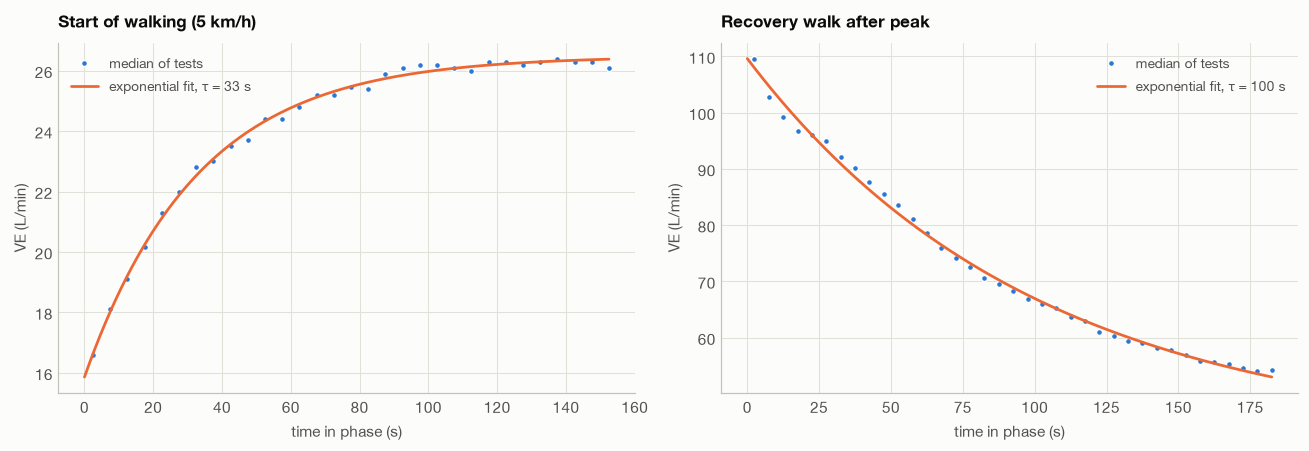

on-kinetics τ ≈ 33 s; walking steady state ≈ 26.3 L/min
→ ramp VE at v ≈ steady-state VE at v − 0.55 km/h (ramp 1.00 km/h/min)
recovery off-kinetics τ ≈ 100 s; extra air in first 3 min after peak: median 137 L (IQR 109-166)


In [17]:
mono = lambda t, base, amp, tau: base + amp * (1 - np.exp(-t / tau))
decay = lambda t, base, amp, tau: base + amp * np.exp(-t / tau)

# warm-up: tests whose walking stage lasts >= 150 s, VE vs time since walking started
wu_ids = dur.index[dur.warmup >= 150]
wu = m[m.ID_test.isin(wu_ids) & (m.phase == "warmup") & (m.t_phase <= 150)]
wu_curve = wu.groupby((wu.t_phase // 5) * 5 + 2.5).VE.median()
p_on, _ = curve_fit(mono, wu_curve.index, wu_curve.values, p0=[10, 10, 30])

# recovery: walking at 4.9-5 km/h after peak, >= 150 s of data
rec_ids = dur.index[dur.recovery >= 150]
rec = m[m.ID_test.isin(rec_ids) & (m.phase == "recovery") & m.Speed.between(4.85, 5.05) & (m.t_phase <= 180)]
rec_curve = rec.groupby((rec.t_phase // 5) * 5 + 2.5).VE.median()
p_off, _ = curve_fit(decay, rec_curve.index, rec_curve.values, p0=[40, 80, 60])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, cur, f, p, title in [(axes[0], wu_curve, mono, p_on, "Start of walking (5 km/h)"),
                             (axes[1], rec_curve, decay, p_off, "Recovery walk after peak")]:
    ax.plot(cur.index, cur.values, "o", ms=4, color=C[0], mec=SURF, mew=1, label="median of tests")
    tt = np.linspace(0, cur.index.max(), 200)
    ax.plot(tt, f(tt, *p), color=C[1], label=f"exponential fit, τ = {p[2]:.0f} s")
    ax.set(xlabel="time in phase (s)", ylabel="VE (L/min)", title=title)
    ax.legend(loc="best")
fig.tight_layout()
plt.show()

walk_ss = wu_curve.loc[120:].mean()
ramp_rate = tests.ramp_rate.median()
print(f"on-kinetics τ ≈ {p_on[2]:.0f} s; walking steady state ≈ {walk_ss:.1f} L/min")
print(f"→ ramp VE at v ≈ steady-state VE at v − {ramp_rate * p_on[2] / 60:.2f} km/h (ramp {ramp_rate:.2f} km/h/min)")

# extra air during the first 3 min of recovery, above walking steady state, per test
rec_t = m[m.ID_test.isin(rec_ids) & (m.phase == "recovery") & (m.t_phase <= 180)].copy()
rec_t["dt"] = rec_t.groupby("ID_test").time.diff().fillna(0) / 60
extra = ((rec_t.VE - walk_ss).clip(lower=0) * rec_t.dt).groupby(rec_t.ID_test).sum()
print(f"recovery off-kinetics τ ≈ {p_off[2]:.0f} s; extra air in first 3 min after peak: "
      f"median {extra.median():.0f} L (IQR {extra.quantile(.25):.0f}-{extra.quantile(.75):.0f})")

## 12. Predicting VE from what the app knows

Cross-validated by subject (GroupKFold on `ID`, 5 folds), so no person appears in both train and test. Feature sets
match what each user might provide. The lab-only VO2 + VCO2 row is a ceiling, not an option for the app.

Two model families:

* **Formula**: OLS on log VE with piecewise-linear (hinge) terms in speed or HR plus profile terms. Easy to drop into the engine as a few
  coefficients.
* **Gradient boosting** (`HistGradientBoostingRegressor`): flexible, tells us how much the formula leaves behind.

In [18]:
FEATS = {
    "speed only": ["Speed"],
    "speed + profile": ["Speed", "Age", "Sex", "Weight", "Height"],
    "HR + profile": ["HR", "Age", "Sex", "Weight", "Height"],
    "speed + HR + profile": ["Speed", "HR", "Age", "Sex", "Weight", "Height"],
    "lab ceiling: VO2 + VCO2": ["VO2", "VCO2"],
}
all_feats = sorted({f for fs in FEATS.values() for f in fs})
md_ = ex.dropna(subset=all_feats + ["VE"]).reset_index(drop=True)
y = md_.VE.to_numpy()
folds = list(GroupKFold(n_splits=5).split(md_, y, groups=md_.ID))


KNOTS = {"Speed": [6.5, 8, 10, 13, 16], "HR": [100, 120, 140, 160, 180]}


def design(df, feats):
    # formula design: piecewise-linear (hinge) terms in the main driver, log weight, other terms linear
    X = pd.DataFrame(index=df.index)
    for f in feats:
        if f in KNOTS:
            X[f] = df[f]
            for k in KNOTS[f]:
                X[f"max(0,{f}-{k})"] = (df[f] - k).clip(lower=0)
        elif f == "Weight":
            X["logW"] = np.log(df.Weight)
        else:
            X[f] = df[f]
    if "Speed" in feats and "HR" in feats:
        X["Speed*HR"] = df.Speed * df.HR
    return X


def cv_predict(make, feats, log_target):
    pred = np.empty_like(y)
    for tr, te in folds:
        Xtr = design(md_.iloc[tr], feats) if log_target else md_.iloc[tr][feats]
        Xte = design(md_.iloc[te], feats) if log_target else md_.iloc[te][feats]
        mdl = make().fit(Xtr, np.log(y[tr]) if log_target else y[tr])
        if log_target:
            smear = np.mean(np.exp(np.log(y[tr]) - mdl.predict(Xtr)))   # Duan smearing for back-transform
            pred[te] = np.exp(mdl.predict(Xte)) * smear
        else:
            pred[te] = mdl.predict(Xte)
    return pred


def scores(pred):
    ape = np.abs(pred - y) / y
    return {"MAE L/min": np.mean(np.abs(pred - y)), "median APE %": 100 * np.median(ape),
            "90th pct APE %": 100 * np.quantile(ape, 0.9), "R²": 1 - np.sum((pred - y) ** 2) / np.sum((y - y.mean()) ** 2)}


hgb = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, min_samples_leaf=200, random_state=0)
rows, oof = [], {}
for name, feats in FEATS.items():
    for fam, make, logt in [("formula", LinearRegression, True), ("boosting", hgb, False)]:
        p = cv_predict(make, feats, logt)
        oof[(name, fam)] = p
        rows.append({"features": name, "model": fam, **scores(p)})
res = pd.DataFrame(rows).set_index(["features", "model"])
print(f"{len(md_):,} bins from {md_.ID_test.nunique()} tests / {md_.ID.nunique()} subjects")
display(res.round({"MAE L/min": 1, "median APE %": 1, "90th pct APE %": 1, "R²": 3}))

81,470 bins from 981 tests / 846 subjects


MAE L/min  median APE %  90th pct APE %    R²
features                model                                                  
speed only              formula         9.8          13.2            35.1  0.82
                        boosting        9.7          13.2            34.6  0.82
speed + profile         formula         8.6          11.9            31.0  0.86
                        boosting        9.0          12.2            32.9  0.85
HR + profile            formula        11.2          15.0            40.6  0.76
                        boosting       12.4          16.5            43.4  0.72
speed + HR + profile    formula         8.1          11.0            28.6  0.87
                        boosting        8.5          11.6            30.2  0.86
lab ceiling: VO2 + VCO2 formula         8.3          10.1            26.9  0.81
                        boosting        6.0           7.8            20.0  0.93

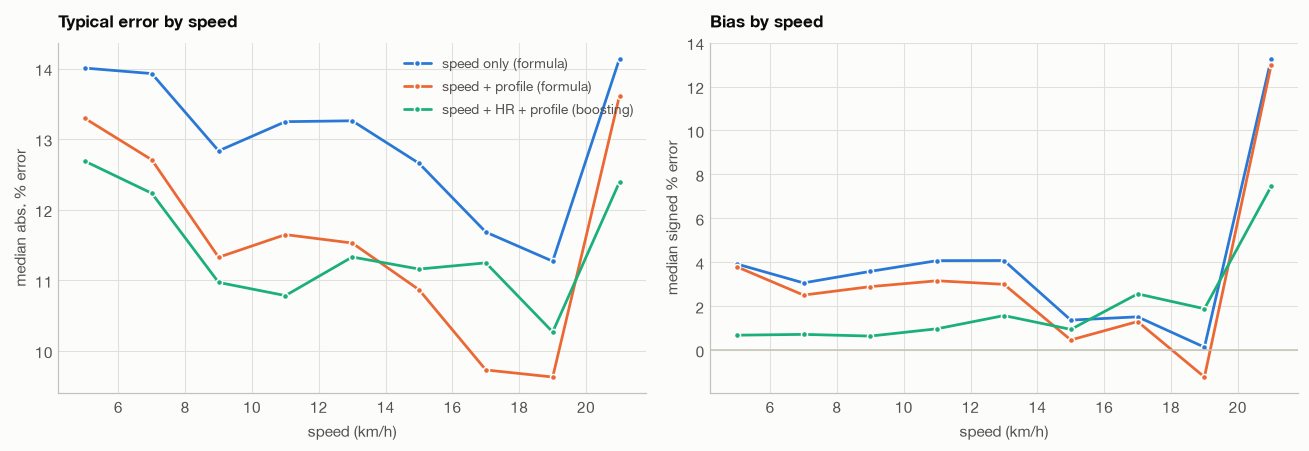

In [19]:
# error by speed band for the app-feasible models
band_edges = np.arange(4, 22.1, 2)
sp_band = pd.cut(md_.Speed, band_edges)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
picks = [("speed only", "formula"), ("speed + profile", "formula"), ("speed + HR + profile", "boosting")]
for k, key in enumerate(picks):
    ape = pd.Series(np.abs(oof[key] - y) / y).groupby(sp_band, observed=True).median()
    bias = pd.Series((oof[key] - y) / y).groupby(sp_band, observed=True).median()
    xm = [iv.mid for iv in ape.index]
    axes[0].plot(xm, ape.values * 100, "o-", ms=4, color=C[k], mec=SURF, mew=1, label=f"{key[0]} ({key[1]})")
    axes[1].plot(xm, bias.values * 100, "o-", ms=4, color=C[k], mec=SURF, mew=1, label=f"{key[0]} ({key[1]})")
axes[0].set(xlabel="speed (km/h)", ylabel="median abs. % error", title="Typical error by speed")
axes[1].axhline(0, color=AXIS, lw=1)
axes[1].set(xlabel="speed (km/h)", ylabel="median signed % error", title="Bias by speed")
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

log(VE) = intercept + Σ coef × term ; VE = exp(...) × 1.0182 (smearing)
valid range: speed 4.9-18.9 km/h, age 11-63, weight 41-135 kg


,coef
intercept,1.20e-01
Speed,1.21e-01
"max(0,Speed-6.5)",1.45e-01
"max(0,Speed-8)",-1.33e-01
"max(0,Speed-10)",-4.69e-02
"max(0,Speed-13)",9.52e-03
"max(0,Speed-16)",-3.22e-02
Age,2.44e-03
Sex,2.98e-02
logW,4.80e-01


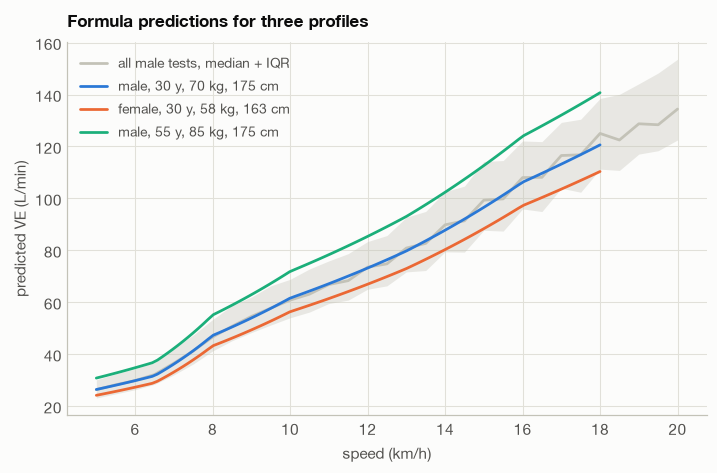

In [20]:
# Fit the speed + profile formula on all data. These coefficients are what the engine would ship.
Xf = design(md_, FEATS["speed + profile"])
form = LinearRegression().fit(Xf, np.log(y))
smear = np.mean(np.exp(np.log(y) - form.predict(Xf)))
coefs = pd.Series(np.r_[form.intercept_, form.coef_], index=["intercept"] + list(Xf.columns))
print("log(VE) = intercept + Σ coef × term ; VE = exp(...) ×", f"{smear:.4f} (smearing)")
print(f"valid range: speed {md_.Speed.quantile(.01):.1f}-{md_.Speed.quantile(.99):.1f} km/h, "
      f"age {md_.Age.min():.0f}-{md_.Age.max():.0f}, weight {md_.Weight.min():.0f}-{md_.Weight.max():.0f} kg")
display(coefs.to_frame("coef").map(lambda c: float(f"{c:.4g}")))


def ve_formula(speed, age, sex, weight, height):
    df = pd.DataFrame({"Speed": np.atleast_1d(speed).astype(float), "Age": age, "Sex": sex, "Weight": weight, "Height": height})
    return np.exp(form.predict(design(df, FEATS["speed + profile"]))) * smear


fig, ax = plt.subplots(figsize=(7.5, 4.4))
band(ax, binned(ex[ex.Sex == 0], "Speed", "VE", edges), AXIS, "all male tests, median + IQR", alpha=0.35)
sp = np.linspace(5, 18, 100)
for k, (lab, kw) in enumerate([("male, 30 y, 70 kg, 175 cm", dict(age=30, sex=0, weight=70, height=175)),
                               ("female, 30 y, 58 kg, 163 cm", dict(age=30, sex=1, weight=58, height=163)),
                               ("male, 55 y, 85 kg, 175 cm", dict(age=55, sex=0, weight=85, height=175))]):
    ax.plot(sp, ve_formula(sp, **kw), color=C[k], label=lab)
ax.set(xlabel="speed (km/h)", ylabel="predicted VE (L/min)", title="Formula predictions for three profiles")
ax.legend(loc="upper left")
plt.show()

## 13. From VE to PM2.5 intake

Air per kilometre = VE × 60 / speed. Going faster shortens exposure time but raises VE. Which wins?

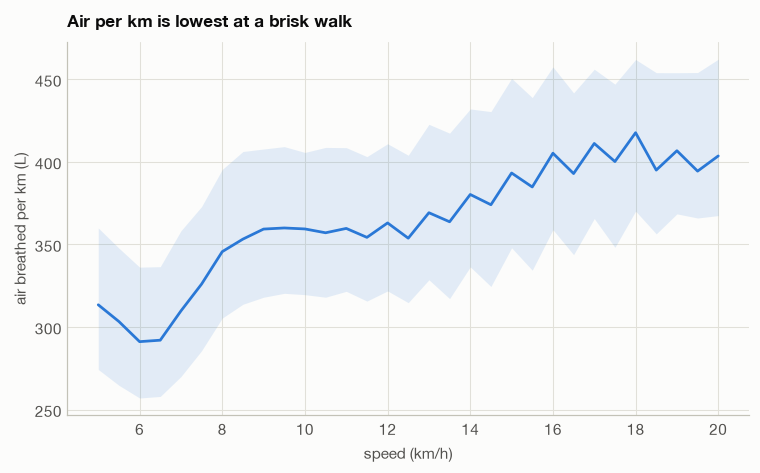

standing rest VE (tests with a rest phase): 12.6 L/min


In [21]:
ex["L_per_km"] = ex.VE * 60 / ex.Speed
fig, ax = plt.subplots(figsize=(8, 4.4))
band(ax, binned(ex, "Speed", "L_per_km", edges), C[0], "median + IQR")
ax.set(xlabel="speed (km/h)", ylabel="air breathed per km (L)", title="Air per km is lowest at a brisk walk")
plt.show()

rest_ve = bins[bins.phase == "rest"].groupby("ID_test").VE.median().median()
print(f"standing rest VE (tests with a rest phase): {rest_ve:.1f} L/min")

In [22]:
# Worked example: 10 km at several paces, PM2.5 = 55 µg/m³, 30 y male, 70 kg, 175 cm.
PM25, DIST = 55.0, 10.0
shift = ramp_rate * p_on[2] / 60   # ramp lag correction, km/h; walking bins are already steady state
rows = []
for label, speed in [("walk 12 min/km", 5.0), ("jog 7 min/km", 60 / 7), ("run 6 min/km", 10.0), ("run 5 min/km", 12.0)]:
    minutes = DIST / speed * 60
    ve = ve_formula(speed, 30, 0, 70, 175)[0]
    ve_ss = ve_formula(speed + (shift if speed > 5.5 else 0.0), 30, 0, 70, 175)[0]
    rows.append({"session": label, "speed km/h": speed, "minutes": minutes, "VE ramp L/min": ve,
                 "VE lag-corrected L/min": ve_ss, "air m³": ve_ss * minutes / 1000,
                 "PM2.5 intake µg": PM25 * ve_ss * minutes / 1000})
rows.append({"session": "sitting, same 70 min", "speed km/h": 0, "minutes": 70, "VE ramp L/min": rest_ve,
             "VE lag-corrected L/min": rest_ve, "air m³": rest_ve * 70 / 1000, "PM2.5 intake µg": PM25 * rest_ve * 70 / 1000})
ex_tbl = pd.DataFrame(rows).set_index("session")
display(ex_tbl.round(1).assign(**{"air m³": ex_tbl["air m³"].round(2)}))

,speed km/h,minutes,VE ramp L/min,VE lag-corrected L/min,air m³,PM2.5 intake µg
session,,,,,,
walk 12 min/km,5.0,120.0,26.4,26.4,3.17,174.1
jog 7 min/km,8.6,70.0,50.9,54.8,3.83,210.9
run 6 min/km,10.0,60.0,61.6,64.6,3.87,213.0
run 5 min/km,12.0,50.0,73.1,76.7,3.83,210.9
"sitting, same 70 min",0.0,70.0,12.6,12.6,0.88,48.6


## 14. Findings

### What VE depends on

* Speed matters most (Spearman ρ = 0.92). Median VE is 26 L/min walking at 5 km/h, 60 at 10 km/h, 73 at 12 and 108
  at 16. It rises 5 to 9 L/min per km/h, with a jump between 7 and 8.5 km/h where people switch from walking to
  running.
* At the same speed, people differ a lot. The middle half of tests spans about ±12% around the median at every speed
  (IQR/median ≈ 0.24). No speed-based estimate can get under that spread without knowing more about the person.
* Fitness is most of that spread. At 12 km/h the least fit third breathes 78.5 L/min and the fittest third 66.8, an 18%
  gap. Once speed and VE are scaled to each person's own peak, all three groups fall on one curve. If the app ever
  learns a user's capacity (a race time, a watch VO2max estimate), relative intensity is the way to use it.
* Body size comes next. In the speed + profile formula VE scales with weight^0.48. With fitness also in the model
  (VE at 10 km/h), it drops to weight^0.26, women breathe 12% less than men of the same size and fitness, and each
  year of age adds 0.16%.
* Lab temperature and humidity show nothing useful (−0.5% per °C, humidity flat). The lab ran 15 to 32 °C indoors at
  ~48% RH, so this says nothing about running at 31 °C and 80% RH in Singapore, where heat pushes VE up.
* VE tracks CO2 output (r = 0.96). VE/VO2 sits near 24 up to about half of peak speed, then climbs to 34 at peak.
  That is why the speed curve steepens at high intensity.
* Tidal volume climbs fast up to about 9 km/h, then only creeps up (2.0 to 2.4 L for men, 1.6 to 1.9 L for women).
  Breathing rate does the rest. RR alone is a weak VE proxy (ρ = 0.80).

### Heart rate helps less than I expected

At a fixed HR, VE spreads wider (IQR/median 0.35) than at a fixed speed (0.24), because fitter people move more air at
the same HR. HR + profile is the worst app-feasible model (15.0% median error). Adding HR to speed + profile only moves
median error from 11.9% to 11.0%. HR is still the fallback when there is no pace (football, cycling, gym circuits).
Each person's VE gain above 120 bpm is a median 1.2 L/min per bpm (IQR 0.96 to 1.45).

### The ACSM chain overshoots

The ACSM running equation gives VO2 12 to 20% above measured at 8 to 16 km/h, and 41% above at 6 km/h where people
are still walking. Pushed through measured VE/VO2, that overestimates VE by 12 to 25%. Ramp lag explains under half of
the gap at 10 km/h. I'd use the fitted formula below rather than ACSM, or at least scale ACSM down.

### Ramp vs steady state

* VE follows a speed change with τ ≈ 33 s. On a 1 km/h per minute ramp, VE at speed v equals steady-state VE at about
  v − 0.55 km/h. The fix is to evaluate the formula at speed + 0.55 for running. That adds 3 to 4 L/min.
* After a maximal effort, VE decays with τ ≈ 100 s. The first 3 minutes of recovery add a median 137 L of extra air
  (IQR 109 to 166). Next to the ~3.8 m³ of a 10 km run that's about 4%, so v1 can ignore it.

### How well VE can be predicted (5-fold CV, split by subject)

| inputs | model | median error | 90th pct error | MAE (L/min) |
|---|---|---|---|---|
| speed only | formula | 13.2% | 35.1% | 9.8 |
| speed + profile | formula | 11.9% | 31.0% | 8.6 |
| HR + profile | formula | 15.0% | 40.6% | 11.2 |
| speed + HR + profile | formula | 11.0% | 28.6% | 8.1 |
| VO2 + VCO2 (lab only) | boosting | 7.8% | 20.0% | 6.0 |

The formula matches gradient boosting on every app-feasible input set, so ship the formula. Median signed error is
about +3% because the back-transformed log model targets the mean, which is the right target for expected intake.

### What this means for dose

* Air per km is lowest at a brisk walk (~290 L/km at 6 to 6.5 km/h), ~360 L/km at 9 to 12 km/h and ~400 L/km at 16+.
  Running faster cuts exposure time, but VE rises more than enough to cancel it.
* Worked example: 30-year-old man, 70 kg, PM2.5 at 55 µg/m³, 10 km. Walking gives 174 µg. Running at 7, 6 or 5 min/km
  gives 211 to 213 µg. For a fixed distance, pace barely matters once you are running, and walking saves about 18%.
  For a fixed time it is a different story: an hour at 6 min/km is 3.9 m³ of air against 0.76 m³ sitting.
* So "slower" only helps if the session is time-boxed. If the distance is fixed, "shorter" or "walk it" are the
  suggestions that actually cut the dose.

### Engine recipe for v1

1. Convert pace to speed in km/h. If above 5.5 km/h, add 0.55 km/h for ramp lag.
2. Compute VE = exp(intercept + Σ coef × term) × 1.018 using the speed + profile coefficients from section 12. Valid
   for 5 to 19 km/h, age 11 to 63, weight 41 to 135 kg.
3. intake (µg) = PM2.5 (µg/m³) × VE / 1000 × minutes.
4. If HR is available, use the speed + HR + profile formula. If only HR, use HR + profile and widen the band.
5. Report about ±12% as typical uncertainty and ±31% as the 90th percentile.

### Caveats

* These are graded maximal ramps, not steady sessions. Over a 60-minute run VE drifts up with heat, fatigue and the
  VO2 slow component. None of that is in this data.
* Indoor treadmill, flat, no wind, mild lab climate. Outdoor heat and humidity in Singapore will raise VE above these
  numbers.
* 85% male, aged 11 to 63, mostly active people. Ageing-centre users (65+) are outside the data. For them I'd treat
  this formula as a rough guide only and check it against published inhalation rates for older adults (e.g. the US EPA
  Exposure Factors Handbook).
* Intake here is inhaled mass. Deposited dose depends on mouth vs nose breathing, which shifts at high VE. Out of scope
  for v1.